# Imports

In [1]:
import complex_dynamics.calculator as dcalc
import complex_dynamics.plot as dplot
import matplotlib.pyplot as plt
import numpy as np
from complex_dynamics.rational_map import RationalMap

In [2]:
plt.style.use("report.mplstyle")

# Ejemplo del libro ($z \mapsto z^2$)

## Puntos fijos

Encontramos los puntos fijos:

In [3]:
R = RationalMap.from_latex("z^2")
print(R)

z^{2}


In [4]:
R_minus_z = RationalMap.from_latex("z^2 - z")
fixed_points = R_minus_z.roots()
fixed_points

array([0.+0.j, 1.+0.j])

In [5]:
R_prime = R.derivative()
critical_points = R_prime.roots()
critical_points

array([0.+0.j])

Note that, according to my methods, it could happen that a root of $R$ is also a pole of $R$ (that is $R$ is not defined at that point). So take care when using my `RationalMap` class for this.

Ahora analizamos su comportamiento. Notar que $\infty$ también es un punto fijo.

In [6]:
print(R_prime)

2 z


$R'(z) = 2x$

In [7]:
z = np.array([0], dtype=np.complex128)
np.abs(R_prime(z))

array([0.])

Cómo $|(R'(0))| = 0 \lt 1 $, $0$ es un punto fijo atractor.

In [8]:
z[0] = 1
np.abs(R_prime(z))

array([2.])

Cómo $|(R'(1))| = 2 \gt 1 $, $1$ es un punto fijo repulsor.

Analizando el caso de $\infty$ a mano, se puede ver que es atractor.

## Regiones de $\mathbb{C}_\infty$

Primero analizaremos las regiones que van a ser más fáciles, $C_1 = \{z : |z| \lt 1 \}$ y $C_2 = \{z : |z| \gt 1 \}$.

Si tenemos $z \in C_1$, es claro que $R^n(z) \to 0$.

In [9]:
r = np.random.uniform(0, 1)
theta = np.random.uniform(0, 2 * np.pi)

z0 = np.complex128(r * np.exp(np.pi * theta * 1j))

In [10]:
max_iterations = 100
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=max_iterations)

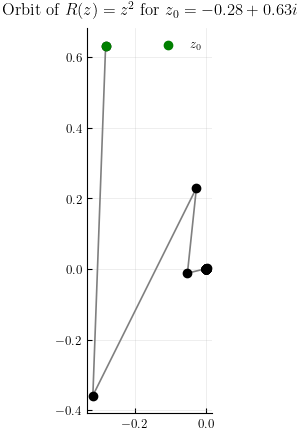

In [11]:
title = rf"Orbit of $R(z) = z^2$ for $z_0 = {np.round(z0.real, 2)} + {np.round(z0.imag, 2)}i$"

fig, ax = dplot.plot_orbit(orbit)
ax.set_title(title, pad=10)
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

Si tenemos $z \in C_2$, es claro que $R^n(z) \to \infty$.

In [12]:
r = np.random.uniform(1, 10)
theta = np.random.uniform(0, 2 * np.pi)

z0 = np.complex128(r * np.exp(np.pi * theta * 1j))

In [13]:
max_iterations = 10
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=max_iterations)

In [14]:
index = 1
for z in orbit:
    print(index, ": ", np.abs(z))
    index += 1

1 :  1.0126158622070245
2 :  1.0253908843932757
3 :  1.051426465796824
4 :  1.1054976129780003
5 :  1.2221249723000565
6 :  1.493589447919414
7 :  2.2308094389362196
8 :  4.976510752846932
9 :  24.765659273201127
10 :  613.3378792362931
11 :  376183.35410607373


Vemos las cuencas de atracción generadas a ordenador para ver el comportamiento para todos los puntos del plano.

In [15]:
center = 0.0
max_distance_to_center = 2

xmin = center.real - max_distance_to_center
xmax = center.real + max_distance_to_center
ymin = center.imag - max_distance_to_center
ymax = center.imag + max_distance_to_center

extent = (xmin, xmax, ymin, ymax)

xpixels = 1000
ypixels = 1000

mesh = dcalc.create_mesh(
    xmin, xmax, ymin, ymax, xpixels=xpixels, ypixels=ypixels
)

In [16]:
attractors = np.array([0, complex(np.inf, 0)], dtype=np.complex128)

max_iterations = int(1e3)
tolerance = 1e-6

convergence_times, convergence_points = dcalc.calculate_convergence_times(
    mesh,
    R,
    attractors=attractors,
    max_iterations=max_iterations,
    tolerance=tolerance,
)

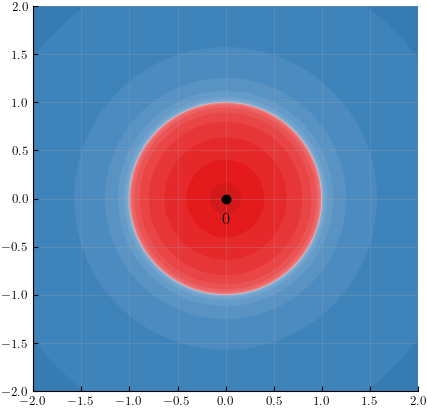

In [17]:
fig, ax = dplot.plot_convergence_times(
    convergence_times,
    convergence_points,
    attractors=attractors,
    max_iterations=max_iterations,
    extent=extent,
)
z0_marker = ax.scatter(0, 0, color="black", zorder=2)
z0_annotation = ax.annotate(
    "0",
    (0, 0),
    xytext=(0, -10),
    textcoords="offset points",
    ha="center",
    va="top",
    fontsize=12,
    zorder=2,
)

Ahora vayamos con el caso interesante, $C = \{z : |z| = 1\}$. Notemos que como $1$ es un punto divergente, la única forma en la que $R^n(z) \to 1$ es si $\exists m$ tal que $R^m(z) = 1$, lo cual equivale a que $z = \exp\left(i \frac{2\pi r}{2^m}\right)$, donde $r$, $m \in \mathbb{N}$. Además, los puntos de esta forma son densos en $C$.

Sin embargo, todos los puntos que no sean de dicha forma (que también son densos en $C$) nunca convergerán en $1$ y tampoco saldrán de $C$. Parte de estos puntos serán puntos periódicos (puntos fijos de $R^n$ para algún $n \in \mathbb{N}$, es decir, $(2^n -1)$-th raíces de la unidad), que son también densos en $C$, y otra parte serán puntos que nunca formarán un ciclo pero tampoco convergerán (que también son densos en $C$), simplemente darán vueltas sin parar y sin nunca repetir un punto, pero siempre dentro de $C$.

Veamos ejemplos para todos estos casos.

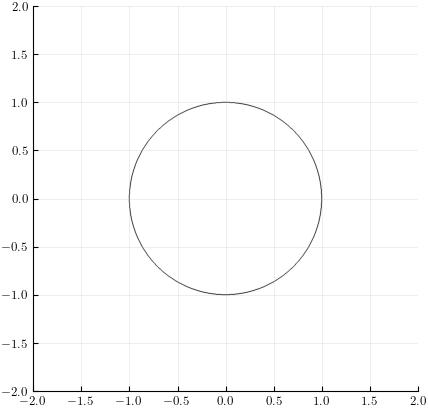

In [18]:
fig, ax = dplot.plot_convergence_points_boundary(
    convergence_points, extent=extent
)

Punto que converge a 1.

In [19]:
m = int(np.random.uniform(0, 11))
r = int(np.random.uniform(0, 2**m))

z0 = np.complex128(np.exp(2j * np.pi * r / (2**m)))

In [20]:
max_iterations = m
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=max_iterations)

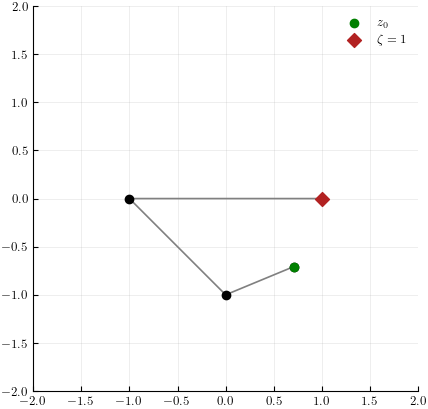

In [21]:
fig, ax = dplot.plot_orbit(orbit)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.scatter(
    1, 0, label=r"$\zeta = 1$", marker="D", color="firebrick", s=50, zorder=2
)
ax.legend()

Punto cíclico.

In [22]:
n = int(np.random.uniform(0, 11))
r = int(np.random.uniform(0, 2**n - 1))

z0 = np.complex128(np.exp(2j * np.pi * r / (2**n - 1)))

In [23]:
max_iterations = n
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=max_iterations)

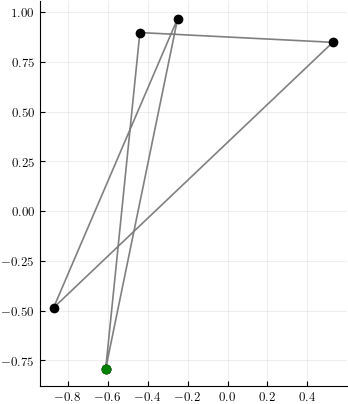

In [24]:
fig, ax = dplot.plot_orbit(orbit)
ax.set_aspect("equal")

Punto no cíclico, no convergente. (eligo uno al azar, estadísticamente lo más probable es que sea no cíclico y no convergente)

In [25]:
theta = np.random.uniform(0, 2 * np.pi)

z0 = np.complex128(np.exp(theta * 1j))

In [26]:
max_iterations = 40
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=max_iterations)

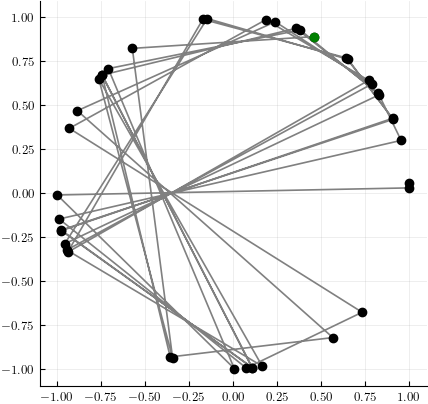

In [27]:
fig, ax = dplot.plot_orbit(orbit)
ax.set_aspect("equal")

# Ejercicio 1

In [28]:
R = RationalMap.from_latex("z^{-2}")
print(R)

\frac{1}{z^{2}}


Los puntos fijos son $\zeta_1 = 1$, $\zeta_2 = \exp\left(i\frac{2\pi}{3}\right)$, $\zeta_3 = \exp\left(i\frac{4\pi}{3}\right)$. Y son todos repulsores. El comportamiento en la circuferencia unidad centrada en $0$ es quedarse ahí. Fuera de este conjunto los puntos se van alejando cada vez más de la circunferencia unidad centrada en $0$ alternando entre estar dentro y fuera de esta. Es decir, se van acercando de manera alternante al $0$ y al $\infty$.

Punto no fijo en la circunferencia unidad centrada en $0$.

In [29]:
r = 1
theta = np.random.uniform()

z0 = np.complex128(np.exp(np.pi * theta * 2j))

In [30]:
max_iterations = 40
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=max_iterations)

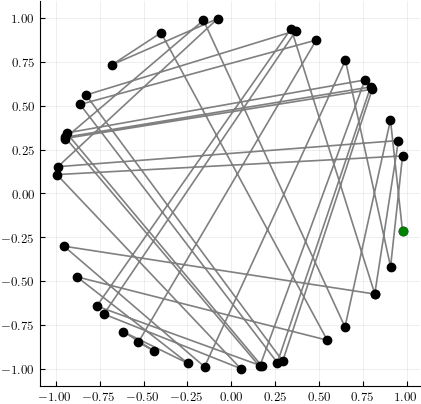

In [31]:
fig, ax = dplot.plot_orbit(orbit)
ax.set_aspect("equal")

Punto fuera de la circunferencia unidad centrada en $0$.

In [32]:
r = np.random.uniform()
theta = np.random.uniform()

z0 = np.complex128(r * np.exp(np.pi * theta * 2j))

In [33]:
max_iterations = 10
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=max_iterations)

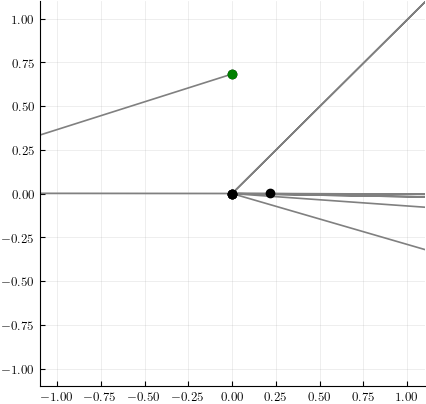

In [34]:
center = 0
max_distance_to_center = 1.1

xmin = center.real - max_distance_to_center
xmax = center.real + max_distance_to_center
ymin = center.imag - max_distance_to_center
ymax = center.imag + max_distance_to_center

fig, ax = dplot.plot_orbit(orbit)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")

In [35]:
plotter = dplot.plot_orbit_on_dynamic_sphere(orbit, show=True)

Widget(value='<iframe src="http://localhost:34347/index.html?ui=P_0x7ffa2efa3550_0&reconnect=auto" class="pyvi…

In [36]:
index = 1
for z in orbit:
    print(index, ": ", abs(z))
    index += 1

1 :  0.6829489258536309
2 :  2.143993909908109
3 :  0.2175469030808109
4 :  21.12974177350411
5 :  0.0022398122772800543
6 :  199331.8779184194
7 :  2.5167871239881025e-11
8 :  1.5787269879036253e+21
9 :  4.0122310418493834e-43
10 :  6.211952592805886e+84
11 :  2.5914553745666086e-170


Si analizamos las iteraciones pares vemos que cada vez son más grandes (porque hemos empezado dentro de la circunferencia, si empezaramos fuera serían cada vez más pequeñas).

In [37]:
index = 1
for z in orbit:
    if index % 2 == 0:
        print(index, ": ", abs(z))
    index += 1

2 :  2.143993909908109
4 :  21.12974177350411
6 :  199331.8779184194
8 :  1.5787269879036253e+21
10 :  6.211952592805886e+84


Si analizamos las iteraciones impares vemos que cada vez son más pequeñas (porque hemos empezado dentro de la circunferencia, si empezaramos fuera serían cada vez más grandes).

In [38]:
index = 1
for z in orbit:
    if index % 2 == 1:
        print(index, ": ", abs(z))
    index += 1

1 :  0.6829489258536309
3 :  0.2175469030808109
5 :  0.0022398122772800543
7 :  2.5167871239881025e-11
9 :  4.0122310418493834e-43
11 :  2.5914553745666086e-170


# Ejercicio 4

In [39]:
R = RationalMap.from_latex("z^2")

Función para encontrar el $z_{-n}$:

In [40]:
def find_zn_negative(R, zeta: complex, z0: complex, n: int):
    theta_zeta = np.angle(zeta)
    theta0 = np.angle(z0)
    r0 = np.abs(z0)

    rn = r0 ** (1 / (2**n))

    k_exact = (theta_zeta * (2**n) - theta0) / (2 * np.pi)
    k_optimal = np.round(k_exact)

    theta_n = (theta0 + 2 * np.pi * k_optimal) / (2**n)

    return rn * np.exp(1j * theta_n)

Probemos para un $\zeta$ aleatorio en la circunferencia unidad y un $z_0$ aleatorio dentro de la circunferencia unidad a encontrar $z_{-10}$.

In [41]:
r = 1
theta = np.random.uniform()

zeta = r * np.exp(2j * np.pi * theta)

In [42]:
r = np.random.uniform(0.5, 1)
theta = np.random.uniform()

z0 = np.complex128(r * np.exp(np.pi * theta * 1j))

In [43]:
n = 10
zn_negative = find_zn_negative(R, zeta, z0, n)

In [44]:
print(abs(zn_negative - zeta))

0.0007387022964032295


Se puede ver que $z_{-10}$ está bastante cerca de $\zeta$.

Ahora pruebo a iterar para ver que efectivamente, de $z_{-10}$ se llega a $z_0$ en 10 iteraciones.

In [45]:
max_iterations = n
orbit = dcalc.calculate_forward_orbit(
    zn_negative,
    R,
    max_iterations=max_iterations,
)

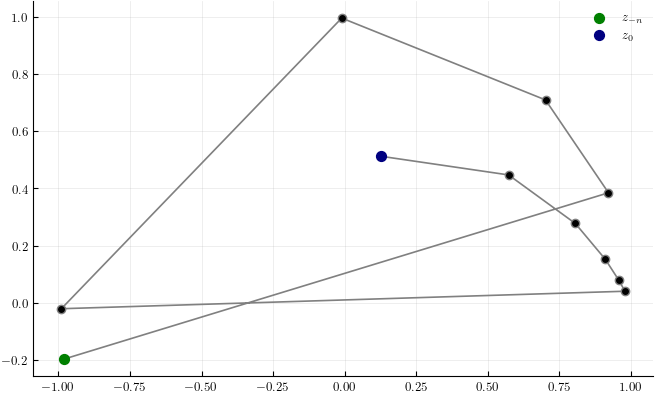

In [46]:
fig, ax = plt.subplots()
ax.plot(
    orbit.real, orbit.imag, marker="o", color="gray", markerfacecolor="black"
)
ax.set_aspect("equal")
ax.scatter(
    zn_negative.real,
    zn_negative.imag,
    label=rf"$z_{{-n}}$",
    marker="o",
    color="green",
    s=50,
    zorder=2,
)
ax.scatter(
    z0.real,
    z0.imag,
    label="$z_0$",
    marker="o",
    color="navy",
    s=50,
    zorder=2,
)
ax.legend()

In [47]:
print(abs(z0), np.angle(z0))
print(abs(orbit[-1]), np.angle(orbit[-1]))

0.5277762460948869 1.325303422305084
0.5277762460949006 1.3253034223056501


Si siguieramos iterando llegaríamos al 0.

In [48]:
max_iterations = 2 * n
orbit = dcalc.calculate_forward_orbit(
    zn_negative,
    R,
    max_iterations=max_iterations,
)

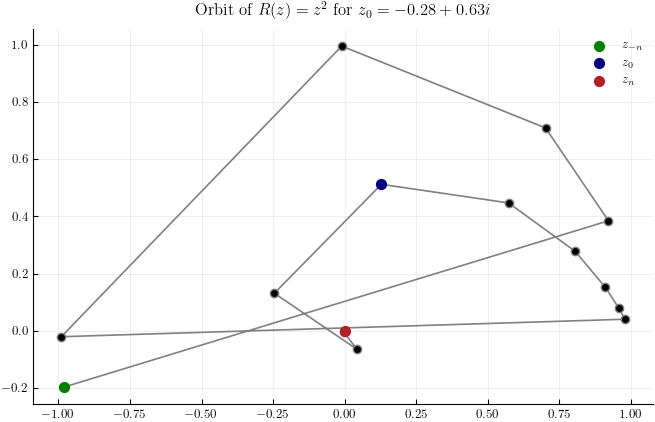

In [49]:
fig, ax = plt.subplots()
ax.plot(
    orbit.real, orbit.imag, marker="o", color="gray", markerfacecolor="black"
)
ax.set_title(title, pad=10)
ax.set_aspect("equal")
ax.scatter(
    zn_negative.real,
    zn_negative.imag,
    label=rf"$z_{{-n}}$",
    marker="o",
    color="green",
    s=50,
    zorder=2,
)
ax.scatter(
    z0.real,
    z0.imag,
    label="$z_0$",
    marker="o",
    color="navy",
    s=50,
    zorder=2,
)
ax.scatter(
    orbit[-1].real,
    orbit[-1].imag,
    label="$z_n$",
    marker="o",
    color="firebrick",
    s=50,
    zorder=2,
)
ax.legend()

Ahora pruebo para un $z_0$ fuera de la circunferencia unidad.

In [50]:
r = 1
theta = np.random.uniform()

zeta = r * np.exp(2j * np.pi * theta)

In [51]:
r = np.random.uniform(1, 10)
theta = np.random.uniform()

z0 = np.complex128(r * np.exp(np.pi * theta * 1j))

In [52]:
n = 10
zn_negative = find_zn_negative(R, zeta, z0, n)

In [53]:
print(abs(zn_negative - zeta))

0.0025268430346446534


Se puede ver que $z_{-10}$ está bastante cerca de $\zeta$.

Ahora pruebo a iterar para ver que efectivamente, de $z_{-10}$ se llega a $z_0$ en 10 iteraciones.

In [54]:
max_iterations = n
orbit = dcalc.calculate_forward_orbit(
    zn_negative,
    R,
    max_iterations=max_iterations,
)

(-10.0, 10.0)

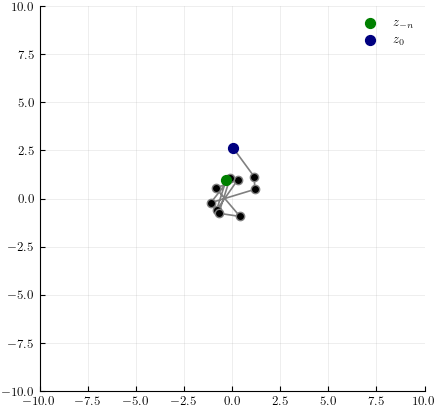

In [55]:
center = 0
max_distance_to_center = 10

xmin = center.real - max_distance_to_center
xmax = center.real + max_distance_to_center
ymin = center.imag - max_distance_to_center
ymax = center.imag + max_distance_to_center

fig, ax = plt.subplots()
ax.plot(
    orbit.real, orbit.imag, marker="o", color="gray", markerfacecolor="black"
)
ax.set_aspect("equal")
ax.scatter(
    zn_negative.real,
    zn_negative.imag,
    label=rf"$z_{{-n}}$",
    marker="o",
    color="green",
    s=50,
    zorder=2,
)
ax.scatter(
    z0.real,
    z0.imag,
    label="$z_0$",
    marker="o",
    color="navy",
    s=50,
    zorder=2,
)
ax.legend()
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

Si siguieramos iterando llegaríamos al $\infty$.

In [56]:
max_iterations = n + 3
orbit = dcalc.calculate_forward_orbit(
    zn_negative,
    R,
    max_iterations=max_iterations,
)

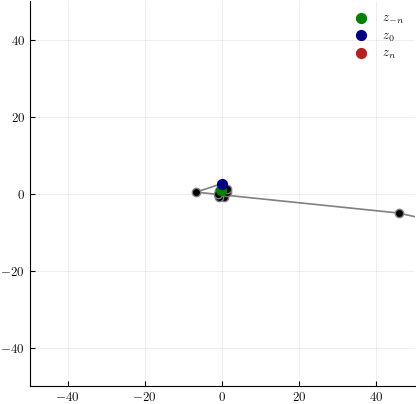

In [57]:
center = 0
max_distance_to_center = 50

xmin = center.real - max_distance_to_center
xmax = center.real + max_distance_to_center
ymin = center.imag - max_distance_to_center
ymax = center.imag + max_distance_to_center

fig, ax = plt.subplots()
ax.plot(
    orbit.real, orbit.imag, marker="o", color="gray", markerfacecolor="black"
)
ax.set_aspect("equal")
ax.scatter(
    zn_negative.real,
    zn_negative.imag,
    label=rf"$z_{{-n}}$",
    marker="o",
    color="green",
    s=50,
    zorder=2,
)
ax.scatter(
    z0.real,
    z0.imag,
    label="$z_0$",
    marker="o",
    color="navy",
    s=50,
    zorder=2,
)
ax.scatter(
    orbit[-1].real,
    orbit[-1].imag,
    label="$z_n$",
    marker="o",
    color="firebrick",
    s=50,
    zorder=2,
)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.legend()

In [58]:
plotter = dplot.plot_orbit_on_dynamic_sphere(orbit, show=True)

Widget(value='<iframe src="http://localhost:34347/index.html?ui=P_0x7ffa0192a290_1&reconnect=auto" class="pyvi…